# Best matched logistic/logistic fits — existing results

This notebook **loads completed experiments only**. It performs no fitting or
new experiment and does not include the new intercept-enabled sweep while it runs.

Eligibility is deliberately strict: logistic loss in both stages, and either
**the identical L2 strength** in both convergence-seeking fits, or **the identical
optimizer and iteration budget** in both finite-iteration fits. No LS auxiliary,
no L1 penalty, and no mismatched fitting procedures are admitted. Intercept choice
must match too. The completed candidates entering this top ten all have **no
intercept**, Delta=1, and equal prior probability for zero/one change.

Rank by mean total-variation distance to the original conditional one-change curve
across two numerical checks. No P(1)>0.5 cutoff is imposed. This is a relative
shape ranking, **not a claim that these ten are good approximations**. Smaller TV
is closer. Numerical ranges are not confidence intervals.

Rows 1–6 are fully solved matched-L2 fits with 30 rho updates and identity rho
initialization. Rows 7–10 are unpenalized, 30-step FISTA in both stages, three rho
updates, and the initialization shown in the table. FISTA has zero coefficient
start and a step ceiling equal to the reciprocal exact global weighted logistic
curvature bound. Finite fitting iterations and rho updates are different quantities.
All likelihood/count-prior conventions remain those in the saved experiments.

Important limitations: the L2 curves remain diffuse, whereas the finite-FISTA
curves are excessively concentrated and some vary substantially with numerical
integration. Moment-equation residuals are shown rather than hidden. The existing
state equations remain heuristic for penalized or early-stopped coefficient fits.


In [1]:
"""Read-only experiment aggregation: rank saved, independently checked curves."""
from pathlib import Path
import json,pickle,hashlib
import numpy as np
import pandas as pd

BASE=Path('results/myocardial_finite_iteration_443c17cf2df6')
OLD=Path('results/myocardial_exploration_4026d0e775d2')
OFFSET=Path('results/myocardial_intercept_exploration_f53f59063391')


def curve_metrics(ages,curve,reference):
    ages=np.asarray(ages,float);curve=np.asarray(curve,float)
    assert len(ages)==len(curve) and len(set(ages))==len(ages)
    assert np.isfinite(curve).all() and np.min(curve)>=0
    np.testing.assert_allclose(curve.sum(),1.,atol=1e-8)
    mapping=dict(zip(ages,curve));support=set(reference)|set(mapping)
    return dict(TV=.5*sum(abs(reference.get(a,0.)-mapping.get(a,0.)) for a in support),
        above55=float(curve[ages>55].sum()),peak=float(ages[np.argmax(curve)]),
        max_probability=float(curve.max()))


def rank_candidates(rows):
    table=pd.DataFrame(rows).sort_values('priority',ascending=False,kind='stable')
    table=table.drop_duplicates('configuration').sort_values(['mean_TV','max_TV','configuration'],kind='stable').reset_index(drop=True)
    table.insert(0,'rank',np.arange(1,len(table)+1));return table


def load_candidates():
    from tools.myocardial_finite_iteration_exploration import load_data,reference_distribution
    reference=reference_distribution();_,_,ages,locations=load_data();all_ages=ages[locations]
    rows=[];curves={}
    def add(first,second,meta,first_path,second_path):
        a=np.asarray(first.get('ages',all_ages),float)
        b=np.asarray(second.get('ages',all_ages),float)
        np.testing.assert_array_equal(a,b)
        p=np.asarray(first['conditional']);q=np.asarray(second['conditional'])
        m=curve_metrics(a,p,reference);n=curve_metrics(a,q,reference)
        probabilities=[float(first['P_1']),float(second['P_1'])]
        assert min(probabilities)>=-1e-8 and max(probabilities)<=1+1e-8
        probabilities=np.clip(probabilities,0,1)
        key=json.dumps({k:meta[k] for k in ('auxiliary','posterior','intercept','Delta','rho_updates','initialization')},sort_keys=True)
        ident=hashlib.sha256((str(first_path)+'|'+str(second_path)).encode()).hexdigest()[:12]
        row=dict(meta,id=ident,configuration=key,P1_min=min(probabilities),P1_max=max(probabilities),
            mean_TV=(m['TV']+n['TV'])/2,max_TV=max(m['TV'],n['TV']),
            numerical_curve_TV=float(.5*np.abs(p-q).sum()),
            mass_above55_min=min(m['above55'],n['above55']),
            peak_min=min(m['peak'],n['peak']),peak_max=max(m['peak'],n['peak']),
            primary_P1=probabilities[0],check_P1=probabilities[1],
            moment_residual=float(first.get('moment_residual',meta.get('moment_residual',np.nan))),
            primary_checkpoint=str(first_path),check_checkpoint=str(second_path))
        rows.append(row);curves[ident]=dict(ages=a,primary=p,check=q)
    stage_dirs={'broad':BASE,'focused':BASE/'focus_354ed8f1e782',
        'initializations':BASE/'initializations_08d005a910b5',
        'fully_solved_matched_L2':BASE/'matched_l2_full_affdef22fb6c'}
    table=pd.read_csv(BASE/'combined_with_full_l2.csv')
    for row in table.itertuples():
        folder=stage_dirs[row.stage]
        if row.stage=='fully_solved_matched_L2':
            paths=[folder/(row.case+'_'+tag+'_score.pkl') for tag in ('q9_seed42','q10_seed123')]
            auxiliary=posterior=f'Logistic L2 {row.strength:.12g} (full solve)'
        else:
            paths=[folder/(row.case+'_'+row.posterior_fit+'_'+tag+'.pkl') for tag in ('q9_seed42','q10_seed123')]
            auxiliary='LS' if row.group=='least_squares' else f'Logistic {"L-BFGS" if str(row.auxiliary).startswith("lbfgs") else "FISTA"} {int(row.auxiliary_budget)} iterations'
            posterior=f'Logistic {"L-BFGS" if row.posterior_fit.startswith("lbfgs") else "FISTA"} {int(row.posterior_budget)} iterations'
        init=row.initialization if pd.notna(row.initialization) else 'identity'
        if init=='scale1_corr0':init='identity'
        add(*[pickle.load(p.open('rb')) for p in paths],dict(
            auxiliary=auxiliary,posterior=posterior,intercept=False,Delta=int(row.Delta),
            rho_updates=int(row.rho_updates),initialization=init,stage=row.stage,priority=3,
            preference_note='No intercept; LS auxiliary' if row.group=='least_squares' else ('No intercept; matched' if row.group in ('logistic_matched','fully_solved_matched_L2') else 'No intercept; different fitting budgets')),*paths)
    # Earlier LS-auxiliary penalty sweeps, retaining every independently checked pair.
    folder=OLD/'denser_penalty_grid'
    for second_path in sorted(folder.glob('*_independent.pkl')):
        first_path=second_path.with_name(second_path.name.replace('_independent.pkl','.pkl'))
        first=pickle.load(first_path.open('rb'));second=pickle.load(second_path.open('rb'))
        case=second['case'];base=pickle.load((OLD/(case+'.pkl')).open('rb'))
        assert base['scenario']['auxiliary']=='least_squares'
        add(first,second,dict(auxiliary='LS',posterior=f'Logistic {first["penalty"].upper()} {first["strength"]:.12g} (full solve)',
            intercept=False,Delta=1,rho_updates=int(base['scenario']['iteration']),initialization='identity',
            stage='earlier_LS_penalty',priority=2,preference_note='No intercept; LS auxiliary',
            moment_residual=base['scenario']['moment_residual']),first_path,second_path)
    # Earlier intercept-aware fits: explicitly flag preference violations, never
    # silently reclassify them as no-intercept or matched-penalty candidates.
    folder=OFFSET/'penalty_resolution'
    for first_path in sorted(folder.glob('*_seed42_q9.pkl')):
        second_path=first_path.with_name(first_path.name.replace('_seed42_q9.pkl','_seed123_q10.pkl'))
        if not second_path.exists():continue
        first=pickle.load(first_path.open('rb'));second=pickle.load(second_path.open('rb'))
        rec=pickle.load((OFFSET/(first['case']+'.pkl')).open('rb'));aux=rec['scenario']['auxiliary']
        if aux=='least_squares':auxiliary='LS';note='Uses intercept'
        else:
            family,strength=aux.split('_',1);strength=float(strength)
            auxiliary=f'Logistic {family.upper()} {strength:.12g} (full solve)'
            note='Uses intercept; '+('matched penalties' if family==first['penalty'] and strength==first['strength'] else 'mismatched penalties')
        add(first,second,dict(auxiliary=auxiliary,posterior=f'Logistic {first["penalty"].upper()} {first["strength"]:.12g} (full solve)',
            intercept=True,Delta=1,rho_updates=int(rec['scenario']['iteration']),initialization='identity',
            stage='earlier_intercept',priority=2,preference_note=note),first_path,second_path)
    # Earlier exact-match checks (not all will be competitive on shape).
    folder=OLD/'exact_matching_no_intercept'
    for second_path in sorted(folder.glob('*_independent_score.pkl')):
        first_path=second_path.with_name(second_path.name.replace('_independent_score.pkl','_score.pkl'))
        first=pickle.load(first_path.open('rb'));second=pickle.load(second_path.open('rb'))
        name=f'Logistic {first["penalty"].upper()} {first["strength"]:.12g} (full solve)'
        add(first,second,dict(auxiliary=name,posterior=name,intercept=False,Delta=1,rho_updates=int(first['iteration']),
            initialization='identity',stage='earlier_exact_match',priority=1,preference_note='No intercept; matched penalties'),first_path,second_path)
    ranked=rank_candidates(rows)
    return ranked,curves,reference


def summary_table(ranked):
    result=ranked[['rank','auxiliary','posterior','intercept','Delta','rho_updates']].copy()
    result['P(1) numerical range']=[f'{lo:.3f}–{hi:.3f}' for lo,hi in zip(ranked.P1_min,ranked.P1_max)]
    result['Conditional mode (age)']=[f'{lo:g}' if lo==hi else f'{lo:g}–{hi:g}' for lo,hi in zip(ranked.peak_min,ranked.peak_max)]
    result['Mean TV']=ranked.mean_TV.round(3)
    result['Numerical curve TV']=ranked.numerical_curve_TV.round(3)
    result['Min. mass above 55']=ranked.mass_above55_min.round(3)
    result['Preference notes']=ranked.preference_note
    return result


In [2]:
all_ranked,curves,reference=load_candidates()
eligible=(all_ranked.auxiliary.str.startswith('Logistic ')
          & (all_ranked.auxiliary==all_ranked.posterior)
          & ~all_ranked.auxiliary.str.contains('L1',regex=False)
          & all_ranked.auxiliary.str.contains('L2|FISTA|L-BFGS|GD',regex=True))
ranked=all_ranked[eligible].copy().rename(columns={'rank':'overall_rank'}).reset_index(drop=True)
ranked.insert(0,'rank',np.arange(1,len(ranked)+1))
best=ranked.head(10).copy()
assert len(best)==10
assert (best.auxiliary==best.posterior).all()
assert not best.auxiliary.str.contains('L1|^LS$',regex=True).any()
assert not best.intercept.any(), 'Update explanatory text if new intercept results are added.'
print(f'{len(ranked)} distinct matched no-L1 logistic configurations have two completed numerical checks.')
table=summary_table(best)
table['Rho initialization']=best.initialization
display(table)
report_digest=hashlib.sha256(Path('tools/build_myocardial_matched_best_ones.py').read_bytes()).hexdigest()[:12]
report_root=Path('results')/('myocardial_matched_logistic_best_ones_'+report_digest)
report_root.mkdir(exist_ok=True)
ranked.to_csv(report_root/'all_matched_candidates.csv',index=False)
best.to_csv(report_root/'top_ten.csv',index=False)


/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


23 distinct matched no-L1 logistic configurations have two completed numerical checks.


,rank,auxiliary,posterior,intercept,Delta,rho_updates,P(1) numerical range,Conditional mode (age),Mean TV,Numerical curve TV,Min. mass above 55,Preference notes,Rho initialization
0,1,Logistic L2 4.21696503429e-05 (full solve),Logistic L2 4.21696503429e-05 (full solve),False,1,30,0.511–0.521,66–68,0.649,0.012,0.596,No intercept; matched,identity
1,2,Logistic L2 5.6234132519e-05 (full solve),Logistic L2 5.6234132519e-05 (full solve),False,1,30,0.513–0.525,66–67,0.651,0.015,0.594,No intercept; matched,identity
2,3,Logistic L2 7.49894209332e-05 (full solve),Logistic L2 7.49894209332e-05 (full solve),False,1,30,0.514–0.528,66,0.653,0.018,0.593,No intercept; matched,identity
3,4,Logistic L2 0.0001 (full solve),Logistic L2 0.0001 (full solve),False,1,30,0.515–0.531,65–66,0.655,0.020,0.592,No intercept; matched,identity
4,5,Logistic L2 0.0003 (full solve),Logistic L2 0.0003 (full solve),False,1,30,0.516–0.536,64–66,0.657,0.025,0.589,No intercept; matched,identity
5,6,Logistic L2 0.001 (full solve),Logistic L2 0.001 (full solve),False,1,30,0.517–0.537,64–66,0.658,0.025,0.588,No intercept; matched,identity
6,7,Logistic FISTA 30 iterations,Logistic FISTA 30 iterations,False,1,3,1.000–1.000,81,0.877,0.462,1.000,No intercept; matched,scale10_corr0
7,8,Logistic FISTA 30 iterations,Logistic FISTA 30 iterations,False,1,3,1.000–1.000,81,0.877,0.273,1.000,No intercept; matched,identity
8,9,Logistic FISTA 30 iterations,Logistic FISTA 30 iterations,False,1,3,1.000–1.000,81,0.877,0.311,1.000,No intercept; matched,scale1_corr-0.5
9,10,Logistic FISTA 30 iterations,Logistic FISTA 30 iterations,False,1,3,1.000–1.000,81,0.885,0.063,1.000,No intercept; matched,scale0.1_corr0


Top ten matched fits: common age axes, separate y-axis scales; compare each curve with its gray reference


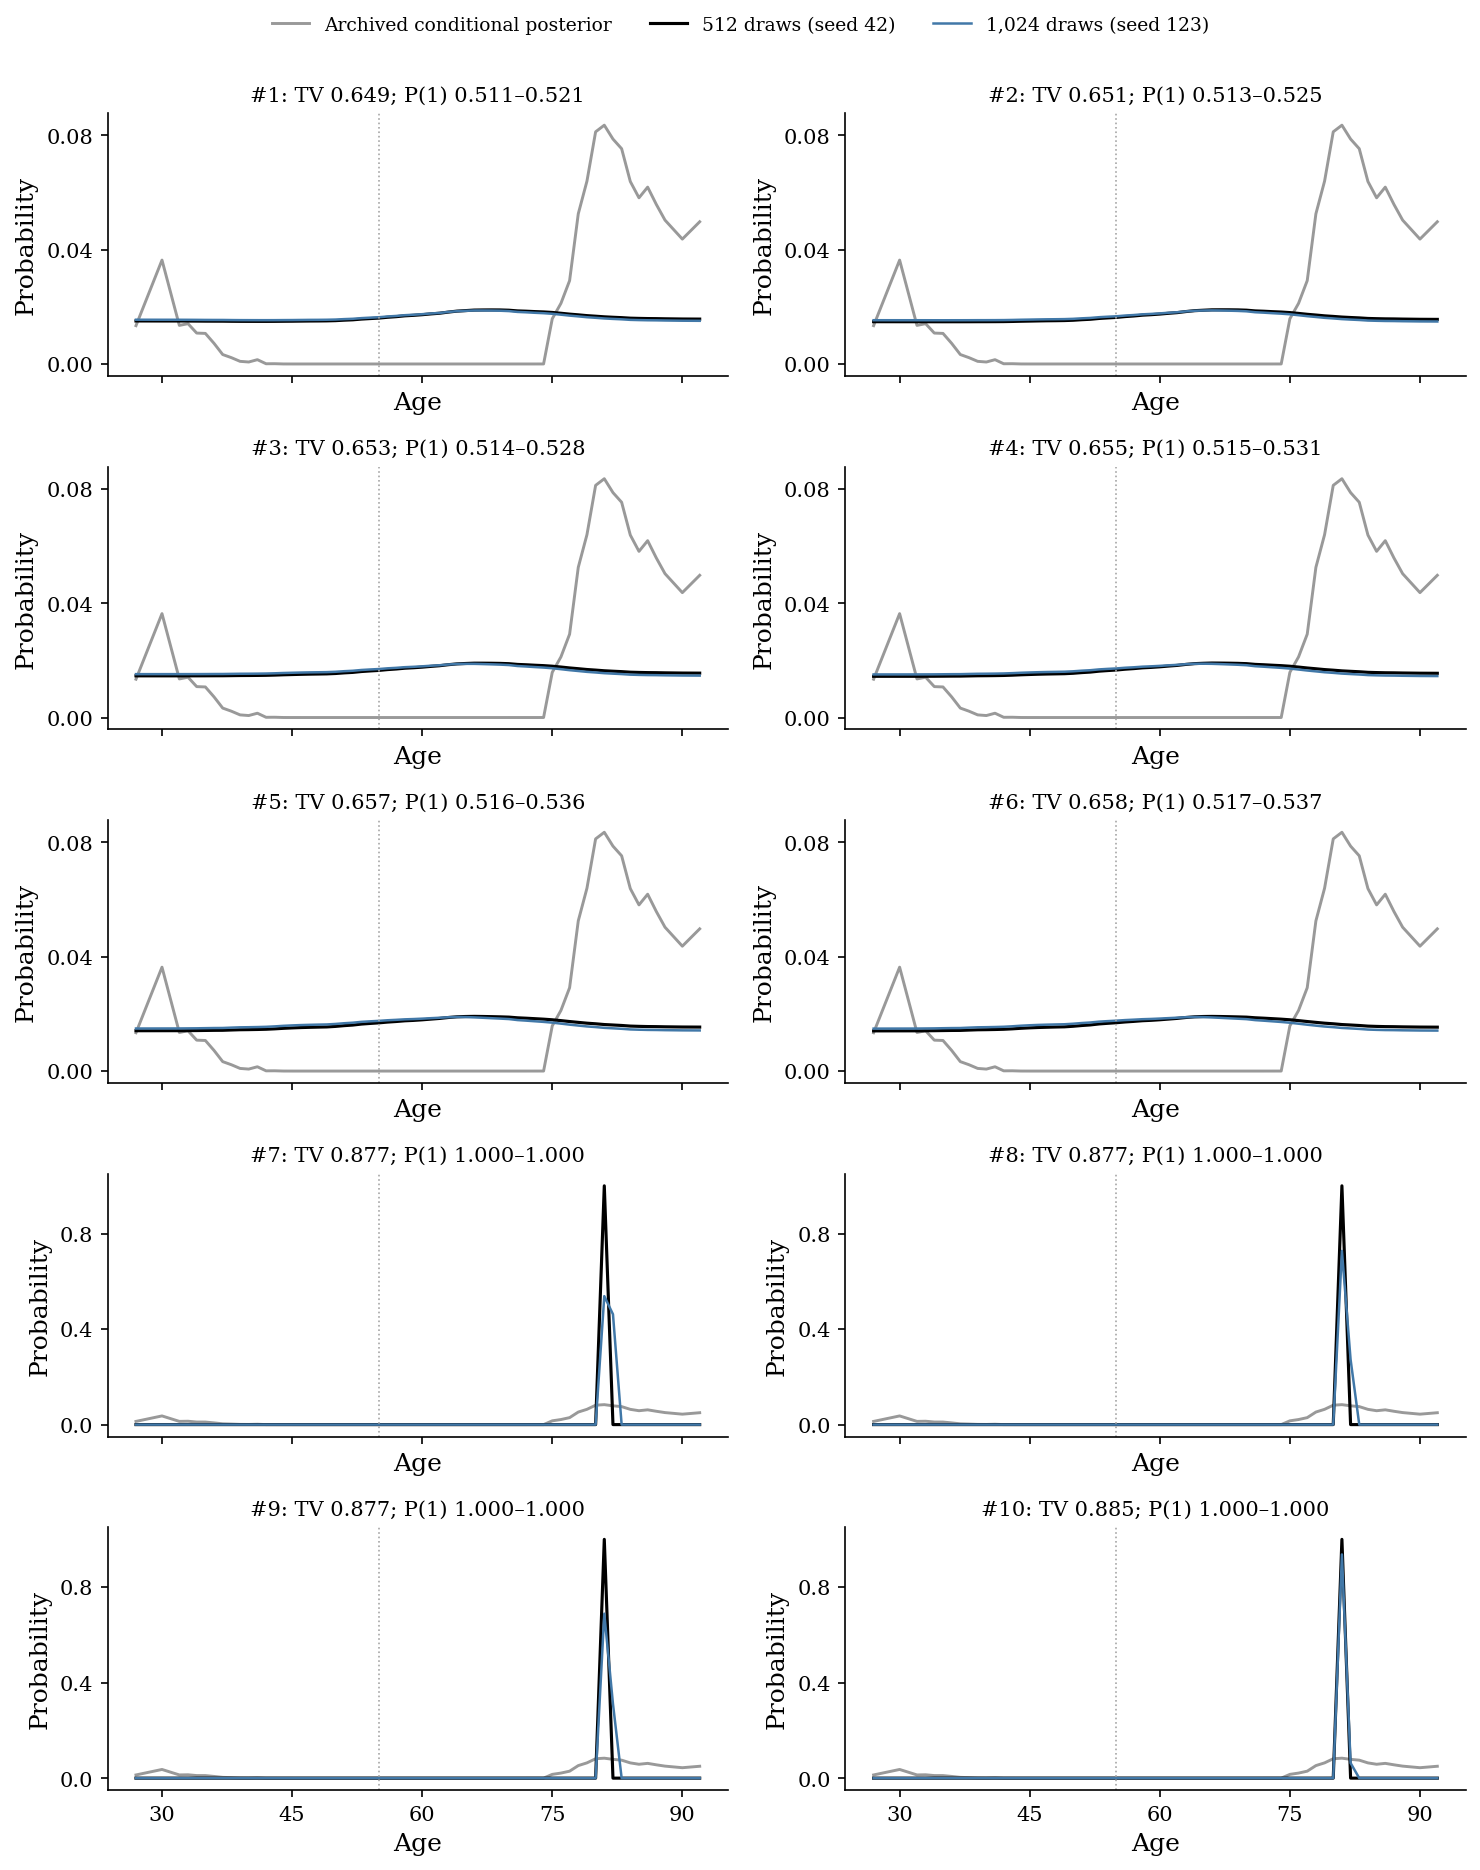

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'axes.labelsize':12,'xtick.labelsize':10,'ytick.labelsize':10,'legend.fontsize':9,
    'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
a=np.array(sorted(reference));p=np.array([reference[x] for x in a])
def aligned(record,key):
    mapping=dict(zip(record['ages'],record[key]))
    return np.array([mapping.get(x,0.) for x in a])
def draw_curves(ax,row,legend=False):
    saved=curves[row.id]
    ax.plot(a,p,color='0.60',lw=1.4,label='Archived conditional posterior')
    ax.plot(a,aligned(saved,'primary'),color='black',lw=1.5,label='512 draws (seed 42)')
    ax.plot(a,aligned(saved,'check'),color='#4178a8',lw=1.2,label='1,024 draws (seed 123)')
    ax.axvline(55,color='0.65',ls=':',lw=.8)
    ax.xaxis.set_major_locator(MaxNLocator(5,integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(3))
    ax.set_xlabel('Age');ax.set_ylabel('Probability')
    if legend:ax.legend(frameon=False,fontsize=8)
print('Top ten matched fits: common age axes, separate y-axis scales; compare each curve with its gray reference')
fig,axes=plt.subplots(5,2,figsize=(10,12.5),sharex=True,sharey=False)
upper=1.08*max([p.max()]+[max(curves[row.id]['primary'].max(),curves[row.id]['check'].max()) for row in best.itertuples()])
for ax,row in zip(axes.flat,best.itertuples()):
    draw_curves(ax,row)
    flag='; intercept' if row.intercept else ''
    ax.set_title(f'#{row.rank}: TV {row.mean_TV:.3f}; P(1) {row.P1_min:.3f}–{row.P1_max:.3f}{flag}',fontsize=10)

handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',ncol=3,frameon=False,fontsize=9)
fig.tight_layout(rect=(0,0,1,.97));plt.show()


Count probability across numerical checks (connecting lines are not confidence intervals)


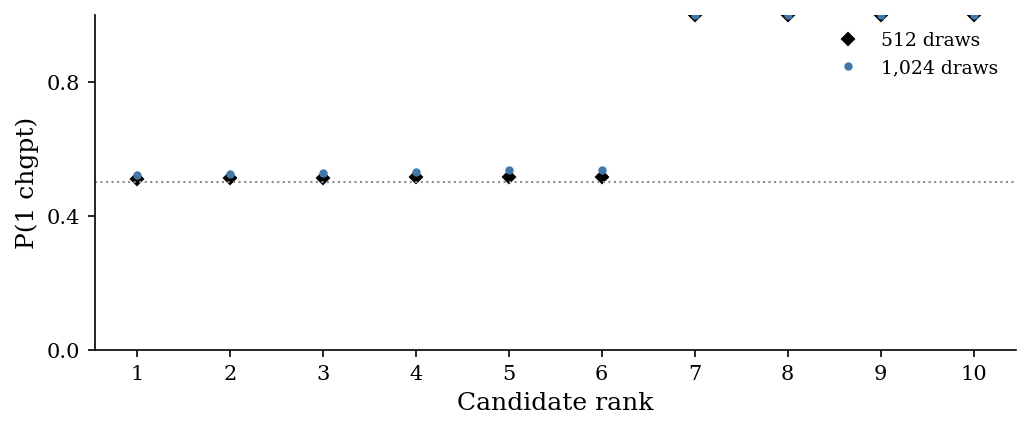

Shape/probability trade-off: rank numbers identify the configurations above


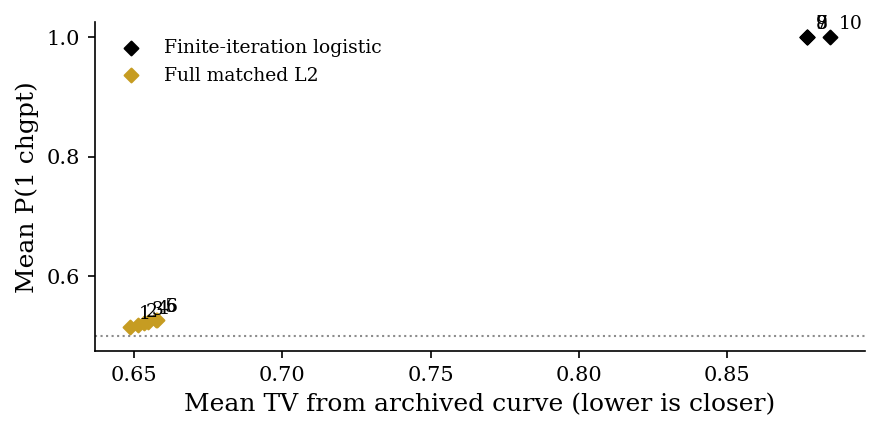

In [4]:
print('Count probability across numerical checks (connecting lines are not confidence intervals)')
fig,ax=plt.subplots(figsize=(7,3))
for row in best.itertuples():
    ax.plot([row.rank,row.rank],[row.P1_min,row.P1_max],color='0.6',lw=1.2)
ax.plot(best['rank'],best.primary_P1,'D',color='black',ms=4,label='512 draws')
ax.plot(best['rank'],best.check_P1,'o',color='#4178a8',ms=3,label='1,024 draws')
ax.axhline(.5,color='0.55',ls=':',lw=1)
ax.set_xticks(best['rank']);ax.set_xlabel('Candidate rank');ax.set_ylabel('P(1 chgpt)')
ax.set_ylim(0,1);ax.yaxis.set_major_locator(MaxNLocator(3));ax.legend(frameon=False)
fig.tight_layout();plt.show()

print('Shape/probability trade-off: rank numbers identify the configurations above')
fig,ax=plt.subplots(figsize=(6,3))
for row in best.itertuples():
    color='#c69c22' if 'L2' in row.posterior else 'black'
    mean_p=(row.P1_min+row.P1_max)/2
    ax.scatter(row.mean_TV,mean_p,color=color,marker='D',s=22)
    ax.annotate(str(row.rank),(row.mean_TV,mean_p),xytext=(4,4),textcoords='offset points',fontsize=9)
ax.axhline(.5,color='0.55',ls=':',lw=1)
ax.set_xlabel('Mean TV from archived curve (lower is closer)');ax.set_ylabel('Mean P(1 chgpt)')
ax.scatter([],[],color='black',marker='D',s=22,label='Finite-iteration logistic')
ax.scatter([],[],color='#c69c22',marker='D',s=22,label='Full matched L2')
ax.legend(frameon=False);ax.yaxis.set_major_locator(MaxNLocator(3))
fig.tight_layout();plt.show()


Individual plots and exact configurations
#1: auxiliary = Logistic L2 4.21696503429e-05 (full solve); posterior-input fit = Logistic L2 4.21696503429e-05 (full solve).
Intercept = False; Delta = 1; rho updates = 30; rho initialization = identity. No intercept; matched.
P(1) = 0.511128–0.520916; mean reference TV = 0.648567; TV between numerical checks = 0.011921; minimum mass above 55 = 0.5963; moment residual = 0.284075.
Reference mass retained by this admissible age grid: 1.0000.


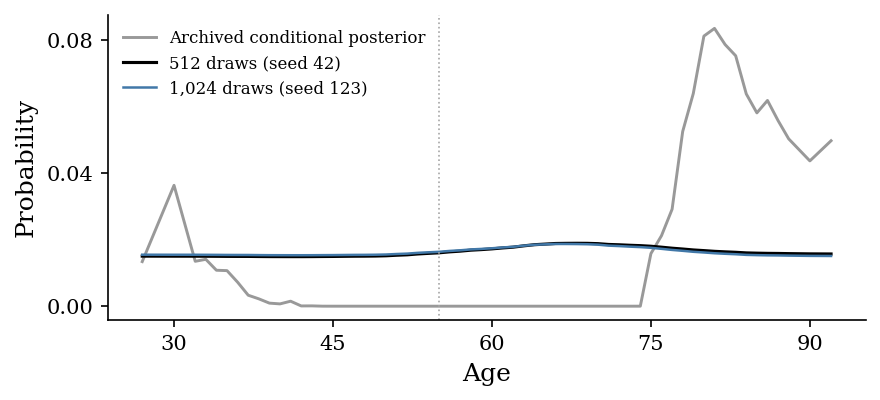

#2: auxiliary = Logistic L2 5.6234132519e-05 (full solve); posterior-input fit = Logistic L2 5.6234132519e-05 (full solve).
Intercept = False; Delta = 1; rho updates = 30; rho initialization = identity. No intercept; matched.
P(1) = 0.512744–0.524969; mean reference TV = 0.651158; TV between numerical checks = 0.015079; minimum mass above 55 = 0.5944; moment residual = 0.367151.
Reference mass retained by this admissible age grid: 1.0000.


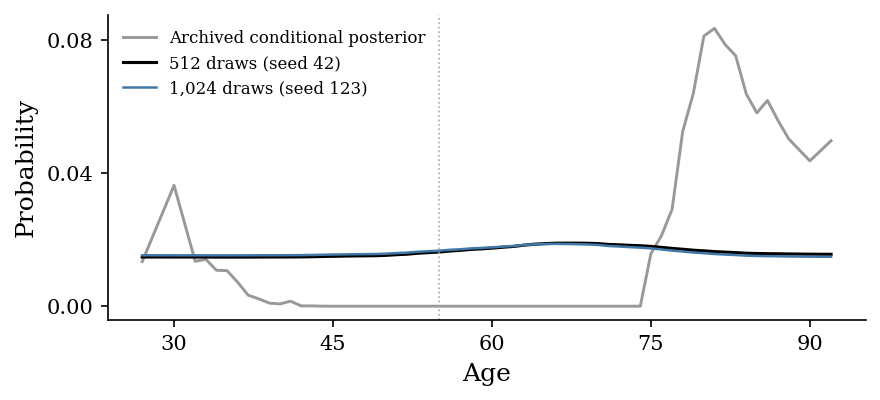

#3: auxiliary = Logistic L2 7.49894209332e-05 (full solve); posterior-input fit = Logistic L2 7.49894209332e-05 (full solve).
Intercept = False; Delta = 1; rho updates = 30; rho initialization = identity. No intercept; matched.
P(1) = 0.513934–0.528315; mean reference TV = 0.653160; TV between numerical checks = 0.017842; minimum mass above 55 = 0.5928; moment residual = 0.437351.
Reference mass retained by this admissible age grid: 1.0000.


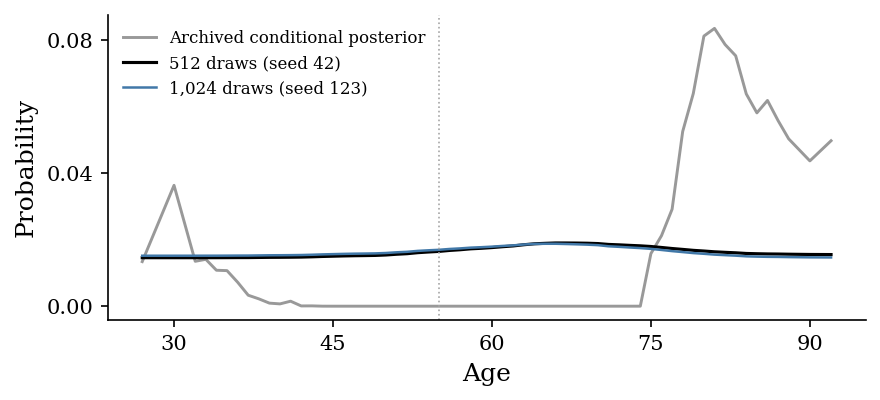

#4: auxiliary = Logistic L2 0.0001 (full solve); posterior-input fit = Logistic L2 0.0001 (full solve).
Intercept = False; Delta = 1; rho updates = 30; rho initialization = identity. No intercept; matched.
P(1) = 0.514800–0.530982; mean reference TV = 0.654661; TV between numerical checks = 0.020131; minimum mass above 55 = 0.5915; moment residual = 0.493835.
Reference mass retained by this admissible age grid: 1.0000.


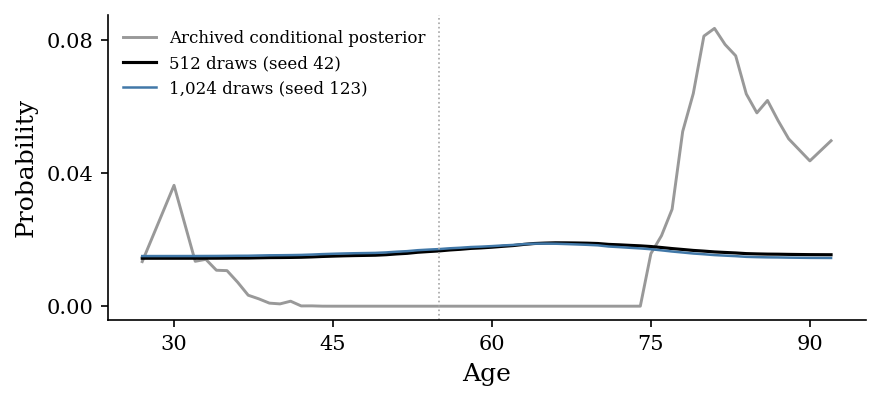

#5: auxiliary = Logistic L2 0.0003 (full solve); posterior-input fit = Logistic L2 0.0003 (full solve).
Intercept = False; Delta = 1; rho updates = 30; rho initialization = identity. No intercept; matched.
P(1) = 0.516320–0.536090; mean reference TV = 0.657259; TV between numerical checks = 0.024646; minimum mass above 55 = 0.5889; moment residual = 0.600446.
Reference mass retained by this admissible age grid: 1.0000.


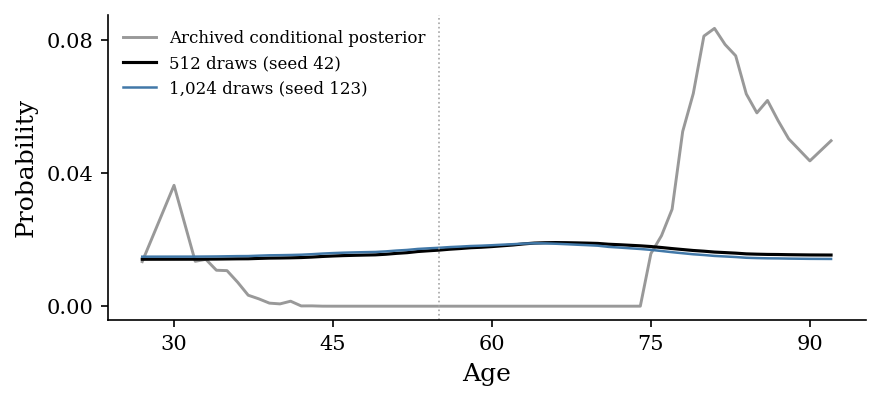

#6: auxiliary = Logistic L2 0.001 (full solve); posterior-input fit = Logistic L2 0.001 (full solve).
Intercept = False; Delta = 1; rho updates = 30; rho initialization = identity. No intercept; matched.
P(1) = 0.516698–0.537052; mean reference TV = 0.657694; TV between numerical checks = 0.025371; minimum mass above 55 = 0.5883; moment residual = 0.616852.
Reference mass retained by this admissible age grid: 1.0000.


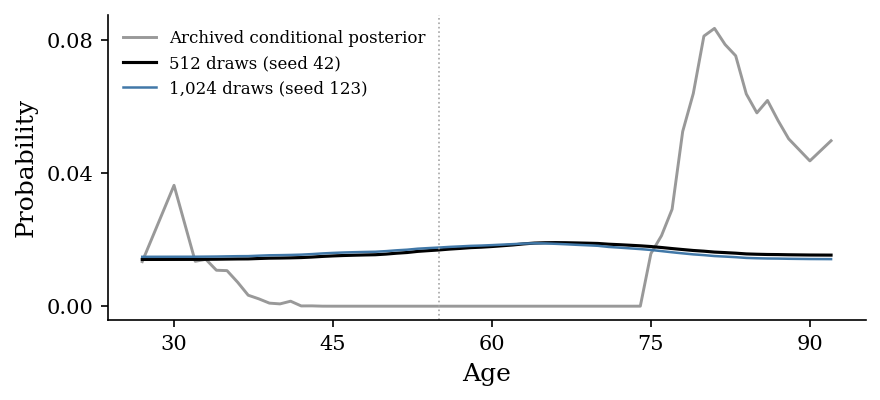

#7: auxiliary = Logistic FISTA 30 iterations; posterior-input fit = Logistic FISTA 30 iterations.
Intercept = False; Delta = 1; rho updates = 3; rho initialization = scale10_corr0. No intercept; matched.
P(1) = 1.000000–1.000000; mean reference TV = 0.877078; TV between numerical checks = 0.462085; minimum mass above 55 = 1.0000; moment residual = 52.879.
Reference mass retained by this admissible age grid: 1.0000.


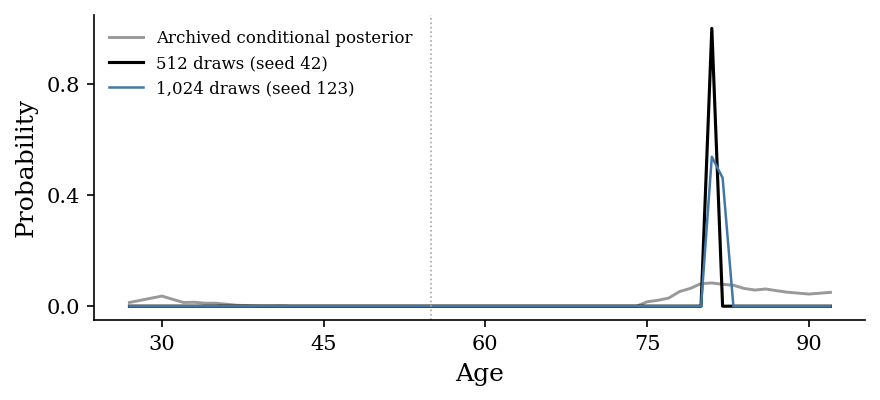

#8: auxiliary = Logistic FISTA 30 iterations; posterior-input fit = Logistic FISTA 30 iterations.
Intercept = False; Delta = 1; rho updates = 3; rho initialization = identity. No intercept; matched.
P(1) = 1.000000–1.000000; mean reference TV = 0.877085; TV between numerical checks = 0.272569; minimum mass above 55 = 1.0000; moment residual = 53.1195.
Reference mass retained by this admissible age grid: 1.0000.


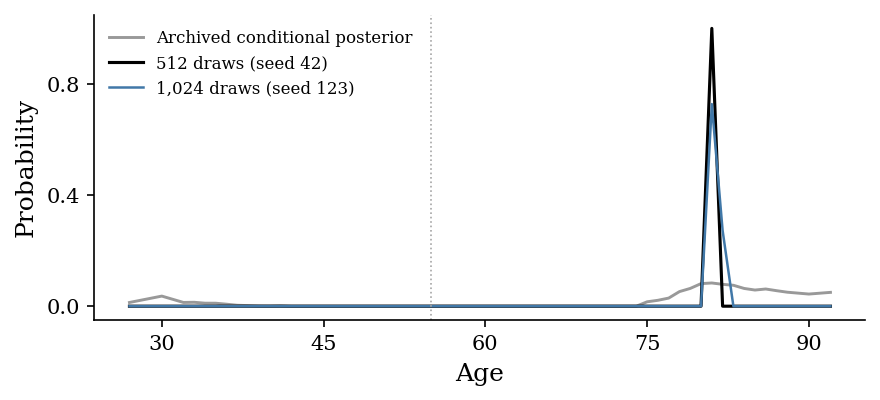

#9: auxiliary = Logistic FISTA 30 iterations; posterior-input fit = Logistic FISTA 30 iterations.
Intercept = False; Delta = 1; rho updates = 3; rho initialization = scale1_corr-0.5. No intercept; matched.
P(1) = 1.000000–1.000000; mean reference TV = 0.877085; TV between numerical checks = 0.311160; minimum mass above 55 = 1.0000; moment residual = 53.1172.
Reference mass retained by this admissible age grid: 1.0000.


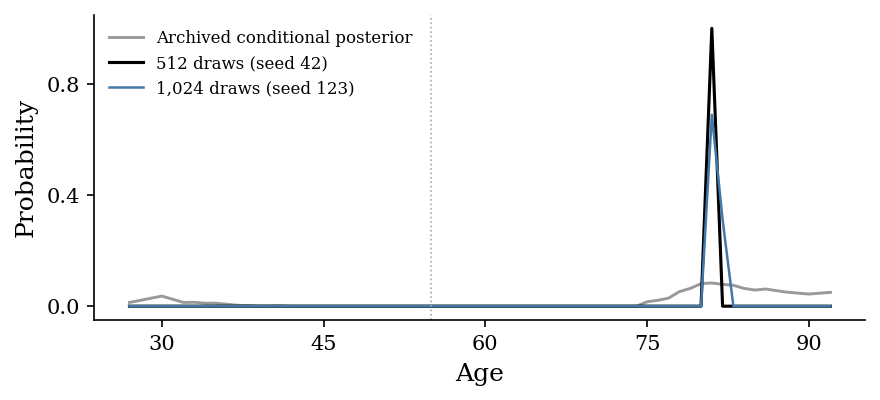

#10: auxiliary = Logistic FISTA 30 iterations; posterior-input fit = Logistic FISTA 30 iterations.
Intercept = False; Delta = 1; rho updates = 3; rho initialization = scale0.1_corr0. No intercept; matched.
P(1) = 1.000000–1.000000; mean reference TV = 0.884771; TV between numerical checks = 0.063281; minimum mass above 55 = 1.0000; moment residual = 53.1096.
Reference mass retained by this admissible age grid: 1.0000.


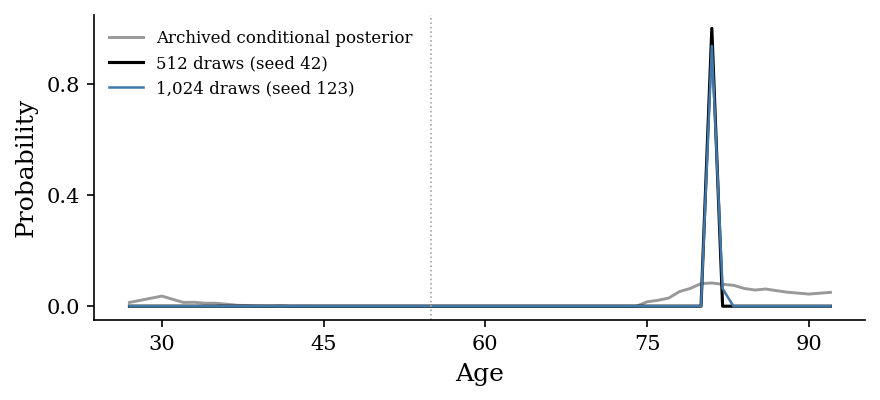

In [5]:
print('Individual plots and exact configurations')
for row in best.itertuples():
    print(f'#{row.rank}: auxiliary = {row.auxiliary}; posterior-input fit = {row.posterior}.')
    print(f'Intercept = {row.intercept}; Delta = {row.Delta}; rho updates = {row.rho_updates}; '
          f'rho initialization = {row.initialization}. {row.preference_note}.')
    print(f'P(1) = {row.P1_min:.6f}–{row.P1_max:.6f}; mean reference TV = {row.mean_TV:.6f}; '
          f'TV between numerical checks = {row.numerical_curve_TV:.6f}; '
          f'minimum mass above 55 = {row.mass_above55_min:.4f}; '
          f'moment residual = {row.moment_residual:.6g}.')
    retained=sum(reference.get(x,0.) for x in curves[row.id]['ages'])
    print(f'Reference mass retained by this admissible age grid: {retained:.4f}.')
    fig,ax=plt.subplots(figsize=(6,2.8));draw_curves(ax,row,legend=True)
    fig.tight_layout();plt.show()


In [6]:
print('Interpretation of the matched-only top ten')
print('The best checked shape is matched L2 approximately 4.22e-5, 30 rho updates, identity start: '
      'P(1) approximately 0.511–0.521, but mean TV approximately 0.649 and a diffuse age-66–68 mode.')
print('Matched FISTA can have an age-81 mode and P(1) near one, but its shape is much too concentrated; '
      'a matching peak alone does not reproduce the original distribution.')
print('Numerical TV below quantifies disagreement between the two integration checks, not sampling uncertainty.')
display(best[['rank','initialization','moment_residual','numerical_curve_TV','primary_checkpoint','check_checkpoint']])
print('Initialization decoding: identity = I; scale10_corr0 = 10 I; scale0.1_corr0 = 0.1 I; '
      'scale1_corr-0.5 = [[1,-0.5],[-0.5,1]].')


Interpretation of the matched-only top ten
The best checked shape is matched L2 approximately 4.22e-5, 30 rho updates, identity start: P(1) approximately 0.511–0.521, but mean TV approximately 0.649 and a diffuse age-66–68 mode.
Matched FISTA can have an age-81 mode and P(1) near one, but its shape is much too concentrated; a matching peak alone does not reproduce the original distribution.
Numerical TV below quantifies disagreement between the two integration checks, not sampling uncertainty.


,rank,initialization,moment_residual,numerical_curve_TV,primary_checkpoint,check_checkpoint
0,1,identity,0.284075,0.011921,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
1,2,identity,0.367151,0.015079,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
2,3,identity,0.437351,0.017842,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
3,4,identity,0.493835,0.020131,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
4,5,identity,0.600446,0.024646,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
5,6,identity,0.616852,0.025371,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
6,7,scale10_corr0,52.878998,0.462085,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
7,8,identity,53.119463,0.272569,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
8,9,scale1_corr-0.5,53.117226,0.311160,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...
9,10,scale0.1_corr0,53.109644,0.063281,results/myocardial_finite_iteration_443c17cf2d...,results/myocardial_finite_iteration_443c17cf2d...


Initialization decoding: identity = I; scale10_corr0 = 10 I; scale0.1_corr0 = 0.1 I; scale1_corr-0.5 = [[1,-0.5],[-0.5,1]].
